In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from IPython.display import Image

In [2]:
df = pd.read_csv("uzbekistan.csv", index_col=0)
df.columns = ['maydon','aholi']
df

,maydon,aholi
Boʻlinishi,,
Andijon viloyati,4200.0,1899000.0
Buxoro viloyati,39400.0,1384700.0
Fargʻona viloyati,6800.0,2597000.0
Jizzax viloyati,20500.0,910500.0
Xorazm viloyati,6300.0,1200000.0
Namangan viloyati,7900.0,1862000.0
Navoiy viloyati,110800.0,767500.0
Qashqadaryo viloyati,28400.0,2029000.0
Qoraqalpogʻiston Respublikasi,160000.0,1200000.0


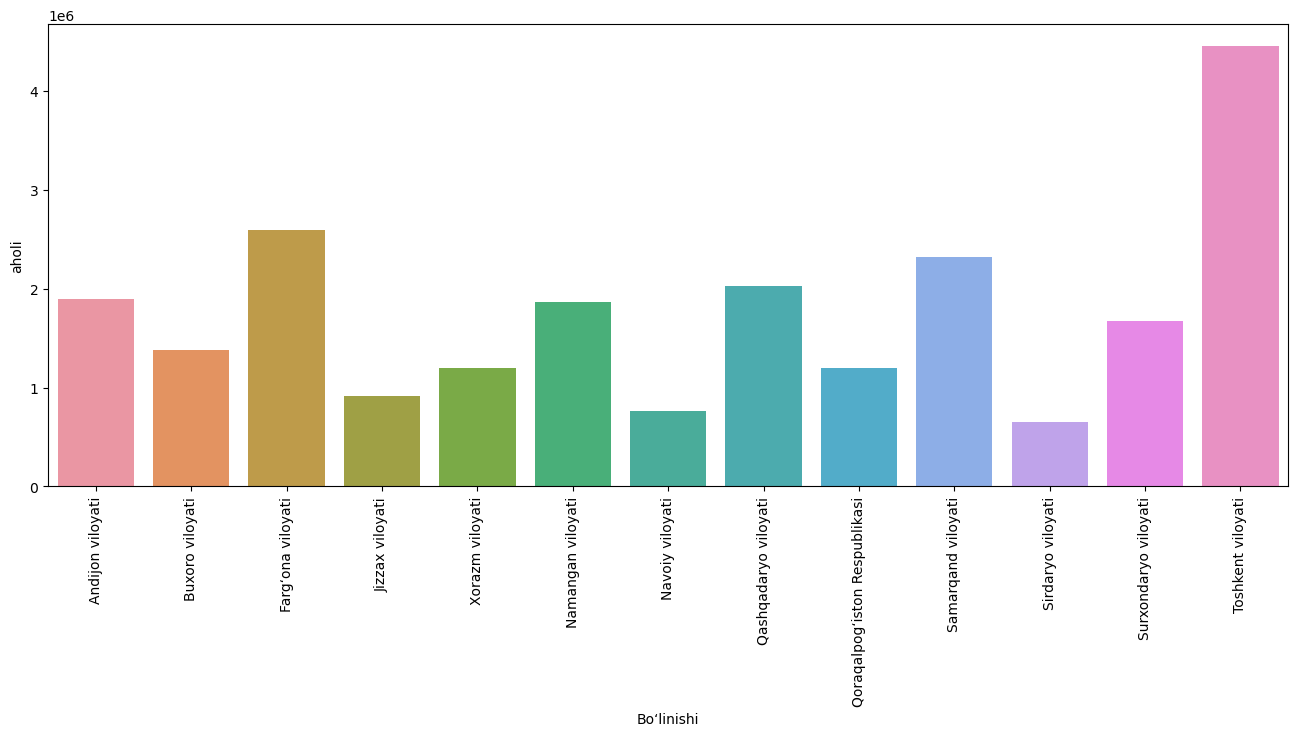

In [3]:
plt.figure(figsize=(16,6))
sns.barplot(x=df.index, y=df.aholi)
plt.xticks(rotation=90)
plt.show()

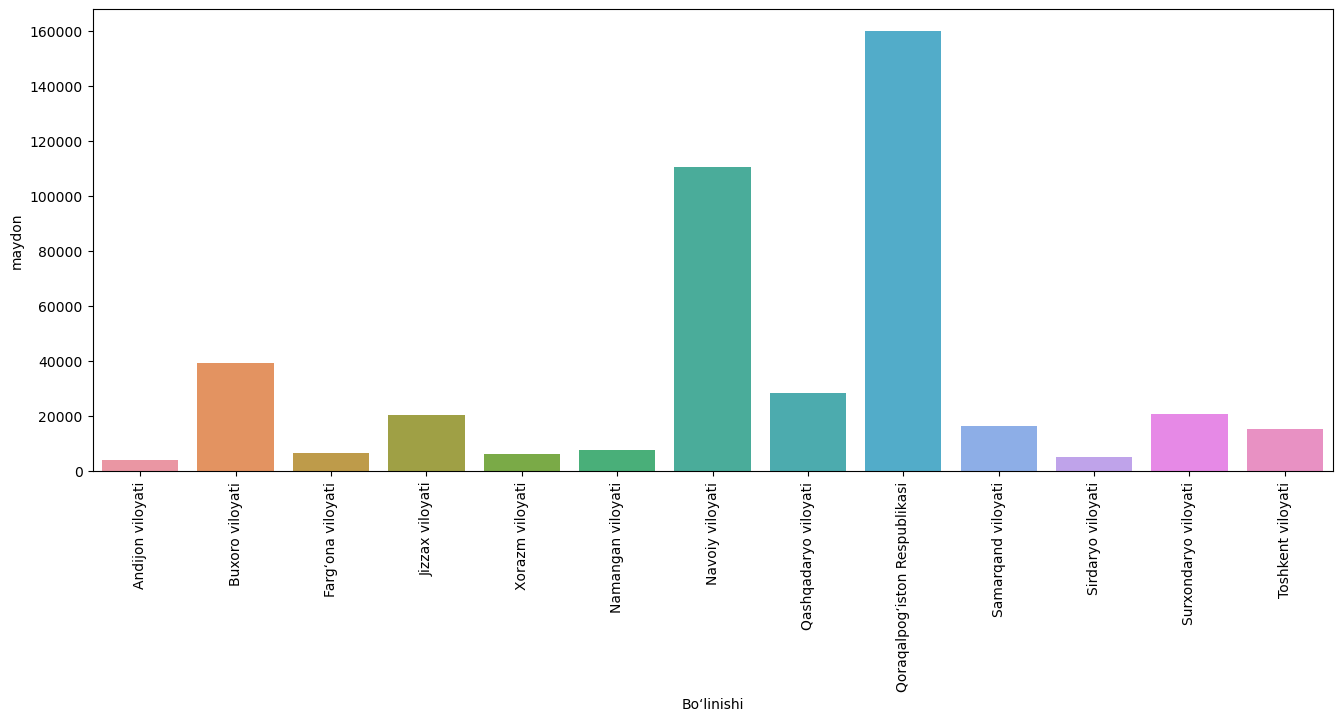

In [4]:
plt.figure(figsize=(16,6))
sns.barplot(x=df.index, y=df['maydon'])
plt.xticks(rotation=90)
plt.show()

## Heatmap

Keling endi yangi jadval o'qiymiz. Quyidagi jadvalda AQSHdagi ba'zi muzeylarga turli sanalarda tashrif buyurganlar soni saqlangan. Biz faqatgina birinchi muzey uchun qiymatlarni o'qiymi ( `usecols=[0,1]`)

# parse_dataset bizga birinchi ustunni typini datetimega utqazib beradi

In [6]:
df = pd.read_csv("museum_visitors.csv", index_col=0, parse_dates=[0], usecols=[0,1])
df.head()

,Avila Adobe
Date,
2014-01-01,24778
2014-02-01,18976
2014-03-01,25231
2014-04-01,26989
2014-05-01,36883


In [7]:
df['month'] = [i.month for i in df.index]
df

,Avila Adobe,month
Date,,
2014-01-01,24778,1
2014-02-01,18976,2
2014-03-01,25231,3
2014-04-01,26989,4
2014-05-01,36883,5
2014-06-01,29487,6
2014-07-01,32378,7
2014-08-01,37680,8
2014-09-01,28473,9


In [8]:
df['year'] = [i.year for i in df.index]
df

,Avila Adobe,month,year
Date,,,
2014-01-01,24778,1,2014
2014-02-01,18976,2,2014
2014-03-01,25231,3,2014
2014-04-01,26989,4,2014
2014-05-01,36883,5,2014
2014-06-01,29487,6,2014
2014-07-01,32378,7,2014
2014-08-01,37680,8,2014
2014-09-01,28473,9,2014


In [9]:
df2 = df.groupby(['month','year']).max()

In [11]:
df2.head()

Avila Adobe
month year             
1     2014        24778
      2015        20438
      2016        19659
      2017        18792
      2018        16265

In [12]:
df2.unstack(level=0)

Avila Adobe                                                        \
month          1        2        3        4        5        6        7    
year                                                                      
2014      24778.0  18976.0  25231.0  26989.0  36883.0  29487.0  32378.0   
2015      20438.0  15578.0  21297.0  26670.0  34383.0  30569.0  41242.0   
2016      19659.0  17378.0  20322.0  24521.0  31728.0  23696.0  31689.0   
2017      18792.0  14035.0  20680.0  25234.0  30029.0  22169.0  30831.0   
2018      16265.0  14718.0  19001.0  18966.0  25173.0  22171.0  23136.0   

                                                    
month       8        9        10       11       12  
year                                                
2014   37680.0  28473.0  27995.0  25691.0  18754.0  
2015   30700.0  20967.0  29764.0  24483.0  21426.0  
2016   25987.0  22897.0  25040.0  17760.0  20107.0  
2017   27009.0  23403.0  22164.0  17629.0  18339.0  
2018   20815.0  21020.0  19280.0  17163.0      NaN

In [13]:
df2.unstack(level=1)

Avila Adobe                                    
year         2014     2015     2016     2017     2018
month                                                
1         24778.0  20438.0  19659.0  18792.0  16265.0
2         18976.0  15578.0  17378.0  14035.0  14718.0
3         25231.0  21297.0  20322.0  20680.0  19001.0
4         26989.0  26670.0  24521.0  25234.0  18966.0
5         36883.0  34383.0  31728.0  30029.0  25173.0
6         29487.0  30569.0  23696.0  22169.0  22171.0
7         32378.0  41242.0  31689.0  30831.0  23136.0
8         37680.0  30700.0  25987.0  27009.0  20815.0
9         28473.0  20967.0  22897.0  23403.0  21020.0
10        27995.0  29764.0  25040.0  22164.0  19280.0
11        25691.0  24483.0  17760.0  17629.0  17163.0
12        18754.0  21426.0  20107.0  18339.0      NaN

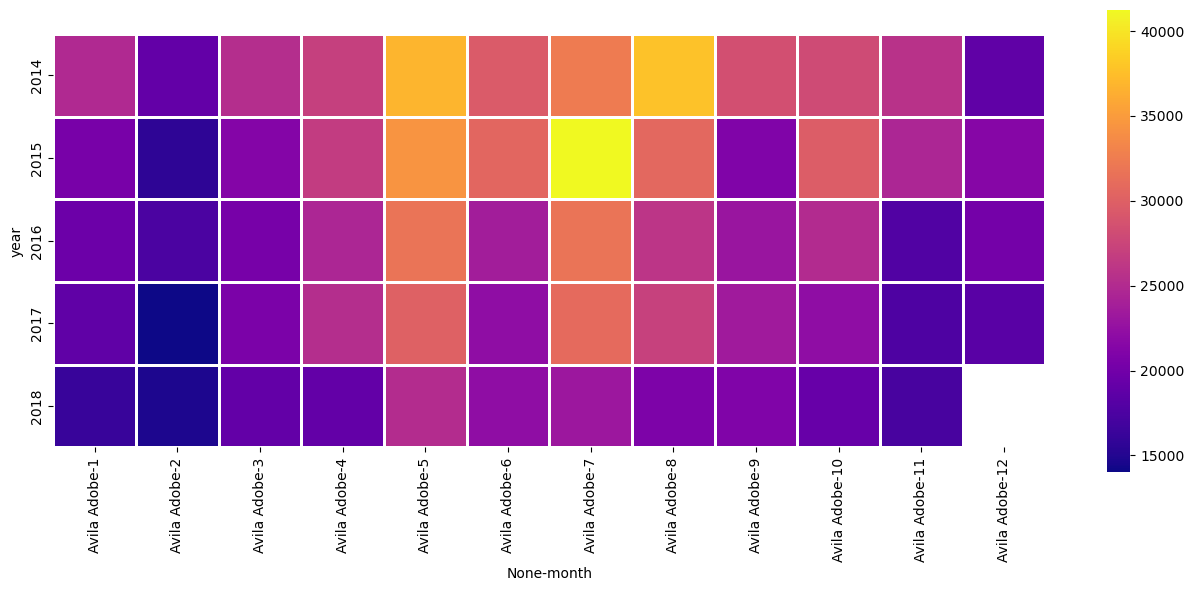

In [16]:
plt.figure(figsize=(16,6))
sns.heatmap(data=df2.unstack(level=0), cmap='plasma', linewidths=1,square=True)
plt.show()

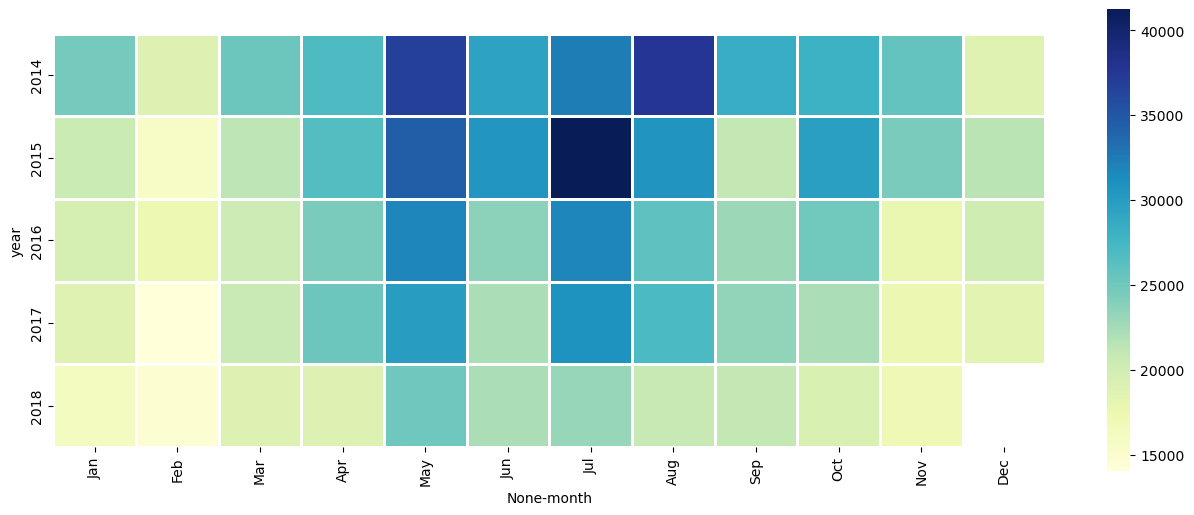

In [18]:
plt.figure(figsize=(16,6))
sns.heatmap(data=df2.unstack(level=0), cmap="YlGnBu", linewidths=1, square=True)
xticks_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.xticks(np.arange(12) + .5, labels=xticks_labels)
plt.show()